# Import

In [35]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import FortranFile
import smplotlib
from hmf import MassFunction
from astropy.cosmology import FlatLambdaCDM, Planck18
import pandas as pd


# Path 

In [34]:
root = Path("..").resolve()
tree_dir = Path("/Users/dexbhadra/Documents/delphi/input_z4p5Tree_files/binary_tree_n_progenitors_mh8to14_2_not_mine")
zgrid = Path("/Users/dexbhadra/Documents/delphi/input_z4p5Tree_files/redshift_grid_mh8to14.bin")
runs = root / "Results_600"

models = {"fiducial": "#E85D9E", "eSFE": "#F2CC45", "eIMF": "#55BCEB"}
#model_color = {"fiducial": "#E85D9E", "eSFE": "#F2CC45", "eIMF": "#55BCEB"}
for model in models:
    print(model, sorted(p.name for p in runs.glob(f"{model}_seed*")))

fiducial ['fiducial_seed12345', 'fiducial_seed13579', 'fiducial_seed24680', 'fiducial_seed32889', 'fiducial_seed98765']
eSFE ['eSFE_seed12345', 'eSFE_seed13579', 'eSFE_seed24680', 'eSFE_seed32889', 'eSFE_seed98765']
eIMF ['eIMF_seed12345', 'eIMF_seed13579', 'eIMF_seed24680', 'eIMF_seed32889', 'eIMF_seed98765']


In [29]:
# same cosmology as module_constants.f90
Om, Ob, Ode, h = 0.30966, 0.04897, 0.68885, 0.6766
G, Msun, Mpc = 6.67e-8, 2.0e33, 3.086e24
a_grain, rho_grain, spin = 5.0e-6, 2.25, 0.04
lam_A, c_A = 1500.0, 2.9979e18
H0_cgs = h * 1e7 / Mpc
cosmo = FlatLambdaCDM(H0=100 * h, Om0=Om, Ob0=Ob, Tcmb0=2.7255)

mass_function = MassFunction(z=4.5, cosmo_model=cosmo,
                            sigma_8=0.811, n=0.965,
                            hmf_model="ST", transfer_model="EH",
                            Mmin=7, Mmax=15, dlog10m=0.01,
                            )

# hmf gives m in Msun/h, so the mass in Msun is m / h; densities are per (cMpc/h)^3, so multiply by h^3.
logM_st = np.log10(mass_function.m / h)
# dn/dlnM is the normalisation that reproduces the paper's UV LFs and SMFs (figure7.ipynb, fresh.pdf Sect. 3).
phi_st = mass_function.dndlnm * h**3
dlogM_tree = 0.01          # the 600 trees are spaced by 0.01 dex, from 10^8.00 to 10^13.99 Msun

In [30]:
with FortranFile(zgrid, "r") as f:
    _ = f.read_ints(np.int32)
    redshifts = f.read_reals(np.float64)

def single_input_tree(p):
    with FortranFile(p, "r") as f:
        _ = int(f.read_ints(np.int32)[0])
        redshift_index_of_halos = f.read_ints(np.int32)
        mass_halos = f.read_reals(np.float64)
        _ = f.read_ints(np.int32)
        _ = f.read_ints(np.int32)
    return redshift_index_of_halos, mass_halos

def read_lum_dust(p):
    with FortranFile(p, "r") as f:
        _sfr = f.read_record(np.float64)
        _mstar = f.read_record(np.float64)
        lum_0 = f.read_record(np.float64)   # ionising photon rate
        lum_1 = f.read_record(np.float64)   # 1300 A
        lum_2 = f.read_record(np.float64)   # 1500 A  <- the UV luminosity
        lum_3 = f.read_record(np.float64)
        lum_4 = f.read_record(np.float64)
        lum_5 = f.read_record(np.float64)
        lum_6 = f.read_record(np.float64)
        _gas_pre = f.read_record(np.float64)
        _gas = f.read_record(np.float64)
        dust = f.read_record(np.float64)
    return lum_2, dust

def Lnu_from_Llambda(L_l):
    return L_l * (lam_A ** 2) / c_A                    # erg/s/A -> erg/s/Hz, at 1500 A

def Muv_from_Lnu(L_nu):
    # AB magnitude at 10 pc, as in figure7.ipynb (fresh.pdf, Eq. 5)
    d_10pc = 10.0 * 3.0857e18
    f_nu = L_nu / (4.0 * np.pi * d_10pc ** 2)
    with np.errstate(divide="ignore"):
        return -2.5 * np.log10(f_nu / 3631e-23)

def tau_uv(mass_halos, z, dust):
    Hz = H0_cgs * np.sqrt(Om * (1 + z) ** 3 + Ode)
    vc = (10.0 * G * mass_halos * Msun * Hz) ** (1.0 / 3.0)
    rvir = G * mass_halos * Msun / vc ** 2
    rgas = 4.5 * spin * rvir * (1 + z) / 6.0
    tau = 3.0 * dust * Msun / (4.0 * np.pi * rgas ** 2 * a_grain * rho_grain)
    return tau

def transmit(tau):
    f = np.ones_like(tau, dtype=float)
    f[tau > 1e-6] = -np.expm1(-tau[tau > 1e-6]) / tau[tau > 1e-6]
    return f

# One point per redshift snapshot

$\rho_{\rm UV}(z) = \sum_{\rm halos} w\,L_\nu$, where $w$ is the number density [cMpc$^{-3}$] represented by the tree the halo belongs to (the same weight as in the UV LF).
- **Intrinsic** (dotted in the paper): every halo, no dust.
- **Observed** (solid): dust-attenuated $L_\nu$, only galaxies with attenuated $M_{\rm UV} < -17$, the limit the observations integrate to.

In [31]:
M_lim = -17.0
snaps = [i + 1 for i, z in enumerate(redshifts) if z < 23]
z_snap = redshifts[np.array(snaps) - 1]

def rho_uv_one_run(results):
    rho_int = np.zeros(len(snaps))
    rho_obs = np.zeros(len(snaps))
    for outp in sorted(results.glob("merger_tree_out_[0-9][0-9][0-9][0-9]")):
        tree_id = int(outp.name.split("_")[-1])
        redshift_index_of_halos, mass_halos = single_input_tree(tree_dir / f"merger_tree_{tree_id:05d}")
        lum_uv, dust = read_lum_dust(outp)
        w = np.interp(np.log10(mass_halos[0]), logM_st, phi_st) * dlogM_tree
        for k, z_i in enumerate(snaps):
            sel = redshift_index_of_halos == z_i
            z = redshifts[z_i - 1]
            L_int = Lnu_from_Llambda(lum_uv[sel])
            L_obs = L_int * transmit(tau_uv(mass_halos[sel], z, dust[sel]))
            rho_int[k] += w * L_int.sum()
            rho_obs[k] += w * L_obs[Muv_from_Lnu(L_obs) < M_lim].sum()
    return rho_int, rho_obs

In [32]:
rho = {}
for model in models:
    seeds = [rho_uv_one_run(p) for p in sorted(runs.glob(f"{model}_seed*")) if (p / "merger_tree_out_0600").exists()]
    if not seeds:
        continue
    rho[model] = dict(int_mean=np.mean([s[0] for s in seeds], axis=0),
                      obs_mean=np.mean([s[1] for s in seeds], axis=0),
                      obs_min=np.min([s[1] for s in seeds], axis=0),
                      obs_max=np.max([s[1] for s in seeds], axis=0))
    print(model, len(seeds), "runs")

fiducial 5 runs
eSFE 5 runs
eIMF 5 runs


# Observations

In [62]:

style = {"whitler25": dict(fmt="o", color="black"),
         "finkelstein24": dict(fmt="<", color="cyan"),
         "mcleod24": dict(fmt="h", color="green"),
         "donnan23":dict(fmt="^", color = "orange")}

In [63]:
# z, log10 rho_UV, lower error, upper error
published = {"mcleod24": [(11.0, 25.15, 0.14, 0.13),
                          (13.5, 24.54, 0.25, 0.16)],
            "finkelstein24": [(9.0, 25.4, 0.1, 0.1),         
                               (11.0, 25.0, 0.2, 0.2),        
                               (14.0, 24.9, 0.7, 1.1)]}

#For Whitler et al. I use Scheter value. 
# Whitler+25, Table 6 (Schechter): rho_UV = x (+hi, -lo) 10^25 erg/s/Hz/Mpc^3
whitler = {10.0: (2.82, 0.33, 0.34), 13.0: (0.90, 0.17, 0.23)}
published["whitler25"] = [(z, np.log10(x * 1e25), -np.log10(1 - lo / x), np.log10(1 + hi / x)) for z, (x, lo, hi) in whitler.items()]


In [64]:
M_grid = np.linspace(-30.0, -17.0, 2601)             # integrate the LF down to M_UV = -17
def Lnu_of_M(M):
    # inverse of the AB absolute magnitude (Oke & Gunn 1983), as Muv_from_Lnu above but backwards:
    # M is the AB magnitude the galaxy would have at d = 10 pc, so its flux there is f_nu = 3631 Jy * 10^(-0.4 M),
    # with 1 Jy = 1e-23 erg/s/cm^2/Hz, and its luminosity is L_nu = 4 pi d^2 f_nu.
    d_10pc = 10.0 * 3.0857e18                          # 10 pc in cm
    f_nu = 3631e-23 * 10 ** (-0.4 * M)                 # erg/s/cm^2/Hz at 10 pc
    return 4.0 * np.pi * d_10pc ** 2 * f_nu            # erg/s/Hz

def rho_dpl(phi_star, M_star, alpha, beta):
    # double power law, Donnan+23 Eq. (2)
    phi = phi_star / (10 ** (0.4 * (alpha + 1) * (M_grid - M_star)) + 10 ** (0.4 * (beta + 1) * (M_grid - M_star)))
    return np.trapezoid(phi * Lnu_of_M(M_grid), M_grid) #Area pf the curve under this region. This is an integrator

In [65]:

# Donnan+23, Table 7: z, phi* [Mpc^-3 mag^-1], M*, alpha, beta (best fits)
donnan = [(8.0, 3.30e-4, -20.02, -2.04, -4.26),
          (9.0, 2.10e-4, -19.93, -2.10, -4.29),
          (10.5, 3.32e-4, -19.12, -2.10, -3.53),
          (13.25, 0.51e-4, -19.12, -2.10, -3.53)]
published["donnan23"] = [(z, np.log10(rho_dpl(p, M, a, b)), 0.0, 0.0) for z, p, M, a, b in donnan]



# Plot

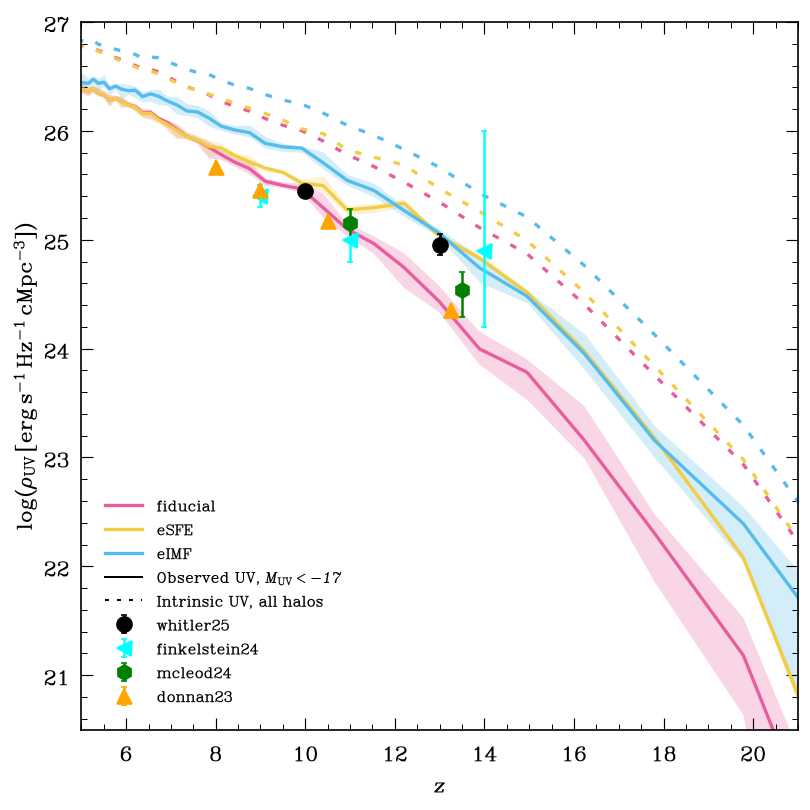

In [67]:
fig, ax = plt.subplots(figsize=(7, 7))
for model, color in models.items():
    if model not in rho:
        continue
    p = rho[model]
    ax.plot(z_snap, np.log10(p["obs_mean"]), "-", color=color, lw=2, label=model)
    ax.fill_between(z_snap, np.log10(p["obs_min"]), np.log10(p["obs_max"]), color=color, alpha=0.25, lw=0)
    ax.plot(z_snap, np.log10(p["int_mean"]), ":", color=color, lw=2)
ax.plot([], [], "-", color="k", label=r"Observed UV, $M_{\rm UV} < -17$")
ax.plot([], [], ":", color="k", label="Intrinsic UV, all halos")
for name in style:
    z, r, lo, hi = np.array(published[name]).T
    ax.errorbar(z, r, yerr=[lo, hi], ms=9, lw=1.5, label=name, **style[name])
ax.set_xlim(5, 21)
ax.set_ylim(20.5, 27)
ax.set_xlabel(r"$z$")
ax.set_ylabel(r"$\log(\rho_{\rm UV}\,[{\rm erg\,s^{-1}\,Hz^{-1}\,cMpc^{-3}}])$")
ax.legend(frameon=False, fontsize=11, loc=3)
fig.tight_layout()
fig.savefig("uvld.png", dpi=200)
plt.show()